In [ ]:
import utils.database as db
from utils import cellmath
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

frame = 39
data = db.get_frame(frame, db.get_database_path())

cell_data = data["cells"]
dbonds_data = data["directed_bonds"]
vertices_data = data["vertices"]

Average Area difference (Magnitude) =  15.011


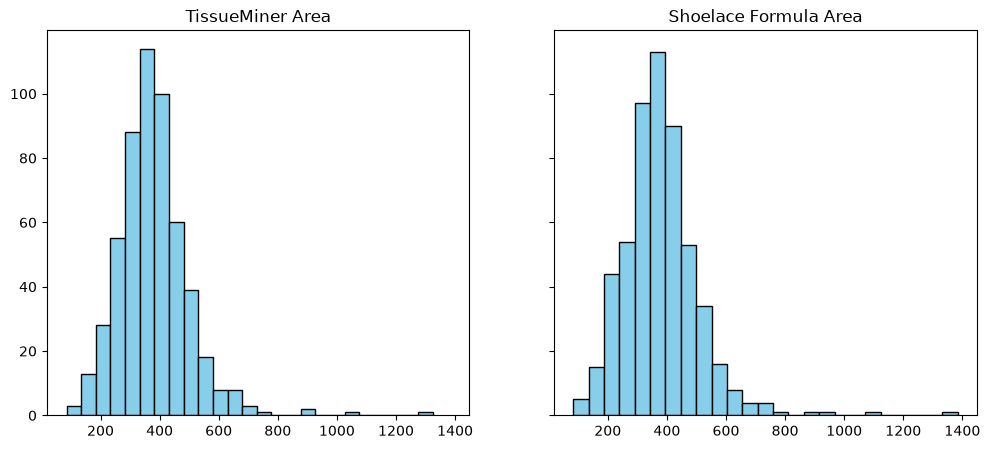

In [41]:
fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True , sharey=True, figsize=(12, 5))

cleaned_cell_data = cell_data[cell_data["cell_id"] != 10000]

ax1.hist(cleaned_cell_data["area"], bins=25, color="skyblue", edgecolor="black")
ax1.set_title("TissueMiner Area")

shoelace_areas = []
for id in cleaned_cell_data["cell_id"]:
    vList = cellmath.get_cell_verticies(id, dbonds_data, vertices_data)
    shoelace_areas.append(cellmath.shoelace_area(vList))


ax2.hist(shoelace_areas, bins=25, color="skyblue", edgecolor="black")
ax2.set_title("Shoelace Formula Area")
    
diff = cleaned_cell_data["area"] - pd.Series(shoelace_areas)

cell_data_area_list  = cleaned_cell_data["area"].tolist()

diff = []
for i, val in enumerate(cell_data_area_list):
    diff.append(shoelace_areas[i] - val)

print("Average Area difference (Magnitude) = ", np.round(np.mean(np.abs(diff)), 3))

(array([ 6.,  7.,  6., 14., 12., 24., 33., 33., 38., 42., 41., 42., 32.,
        29., 36., 32., 27., 34., 16., 10.,  7.,  7.,  8.,  3.,  3.]),
 array([-0.02505552,  0.13928771,  0.30363095,  0.46797418,  0.63231741,
         0.79666064,  0.96100387,  1.1253471 ,  1.28969033,  1.45403356,
         1.61837679,  1.78272003,  1.94706326,  2.11140649,  2.27574972,
         2.44009295,  2.60443618,  2.76877941,  2.93312264,  3.09746588,
         3.26180911,  3.42615234,  3.59049557,  3.7548388 ,  3.91918203,
         4.08352526]),
 <BarContainer object of 25 artists>)

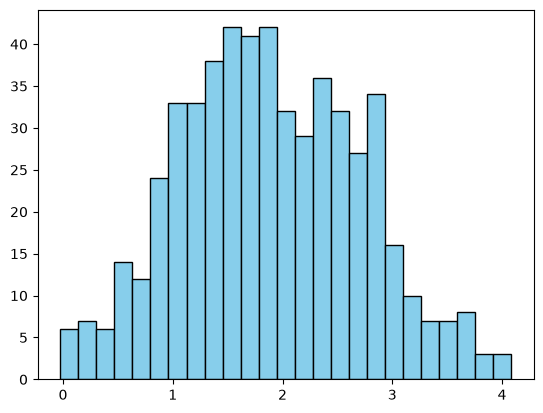

In [42]:
nematic_orders = []
for id in cleaned_cell_data["cell_id"]:
    vList = cellmath.get_cell_verticies(id, dbonds_data, vertices_data)
    real, imaginary = cellmath.nematic_order(vList)
    nematic_orders.append(real)

plt.hist(nematic_orders, bins=25, color="skyblue", edgecolor="black")